# 02 – Predicting hourly demand for the whole city (regression)

**Question:** How many bikes will be taken out in the whole city in a given hour?

- Target: `departures` = the total number of trips that start at any station in that hour.
- Features: hour of day, weekday, month, public holiday, and weather.

We predict the city total instead of each single station, because one station in one hour is mostly 0, 1 or 2 trips and therefore very random. When all stations are added together, most of this randomness cancels out (see section 7). Arrivals are not modelled separately: every trip has both a departure and an arrival, so the two hourly totals are almost identical.

Models (from simple to complex):
1. Baseline: always predict the training average
2. Linear regression (with an hour × type-of-day interaction)
3. Poisson regression (made for count data, same features as linear regression)
4. Decision tree
5. Random forest
6. Gradient boosting

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, PoissonRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

PROCESSED_DIR = Path("../data/processed")
FIG_DIR = Path("../report/figures")

In [2]:
df = pd.read_parquet(PROCESSED_DIR / "station_hourly.parquet")
print(df.shape)
df.head()

(1852877, 17)


,station_id,time,departures,arrivals,date,hour,weekday,month,is_holiday,temperature_2m,relative_humidity_2m,precipitation,snow_depth,cloud_cover,wind_speed_10m,lat,lon
0,377,2025-04-30 03:00:00+00:00,0,0,2025-04-30,5,2,4,0,6.0,82,0.0,0.0,0,1.66,59.915667,10.777567
1,377,2025-04-30 04:00:00+00:00,0,0,2025-04-30,6,2,4,0,5.8,83,0.0,0.0,3,1.54,59.915667,10.777567
2,377,2025-04-30 05:00:00+00:00,0,0,2025-04-30,7,2,4,0,8.0,76,0.0,0.0,77,1.63,59.915667,10.777567
3,377,2025-04-30 06:00:00+00:00,0,0,2025-04-30,8,2,4,0,9.9,64,0.0,0.0,100,1.77,59.915667,10.777567
4,377,2025-04-30 07:00:00+00:00,0,0,2025-04-30,9,2,4,0,11.0,55,0.0,0.0,100,2.33,59.915667,10.777567


## 1. From stations to the whole city

We add up departures and arrivals over all stations for every hour. The time and weather columns are the same for every station in an hour, so we just keep the first value.

In [3]:
weather_features = ["temperature_2m", "relative_humidity_2m", "precipitation", "snow_depth", "cloud_cover", "wind_speed_10m"]
same_for_all_stations = ["date", "hour", "weekday", "month", "is_holiday"] + weather_features

city = (
    df.groupby("time")
    .agg(
        departures=("departures", "sum"),
        arrivals=("arrivals", "sum"),
        **{col: (col, "first") for col in same_for_all_stations},
    )
    .reset_index()
)

# Weekend or public holiday vs normal working day (used for the linear models and the trees)
city["is_weekend"] = ((city["weekday"] >= 5) | (city["is_holiday"] == 1)).astype(int)
city["hour_daytype"] = city["hour"].astype(str) + "_" + np.where(city["is_weekend"] == 1, "weekend", "workday")

print("Hours:", len(city))
print("Correlation between hourly departures and arrivals:", round(city["departures"].corr(city["arrivals"]), 3))
city["departures"].describe().round(1)

Hours: 7295
Correlation between hourly departures and arrivals: 0.993


count    7295.0
mean      152.6
std       156.9
min         1.0
25%        27.0
50%       101.0
75%       227.0
max       933.0
Name: departures, dtype: float64

## 2. Train / test split

Hours next to each other are very similar (same weather, same day). If we split randomly, the test set would contain hours that are almost copies of training hours, and the test error would look too good.

So we split by **date**: the 24th and later of every month is the test set (about 25 % of the data). This way every season is in both train and test, but no day is in both. The city table is small, so all models are trained on the full training set.

In [4]:
is_test = city["date"].dt.day >= 24
train = city[~is_test]
test = city[is_test].copy()

y_train = train["departures"]
y_test = test["departures"]

print("Training hours:", len(train))
print("Test hours:", len(test))

Training hours: 5513
Test hours: 1782


## 3. Features

- **Linear models** cannot use `hour` as a plain number (hour 8 is not "twice" hour 4). We use **one-hot encoding**: one 0/1 column per hour, per weekday and per month. Weather variables are standardised.
- The commuter peaks only happen on working days (notebook 01), so for the linear models the hour is combined with the type of day (`hour_daytype`, workday or weekend/holiday). This is an **interaction**: the model learns one daily curve for working days and another for days off.
- **Tree models** can split on numbers directly, so they get `hour`, `weekday`, `month`, `is_holiday` and `is_weekend` as numbers, together with the weather.

In [5]:
categorical_features = ["hour_daytype", "weekday", "month"]
numeric_features = weather_features + ["is_holiday"]

tree_features = ["hour", "weekday", "month", "is_holiday", "is_weekend"] + weather_features


def make_linear_preprocessing():
    return ColumnTransformer([
        ("categories", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("numbers", StandardScaler(), numeric_features),
    ])


# Cross-validation that keeps all hours of one day in the same fold
cv = GroupKFold(n_splits=5)
train_days = train["date"]

In [6]:
results = []


def evaluate(name, y_pred):
    results.append({
        "model": name,
        "RMSE": root_mean_squared_error(y_test, y_pred),
        "MAE": mean_absolute_error(y_test, y_pred),
        "R2": r2_score(y_test, y_pred),
    })
    print(results[-1])

## 4. Baseline and linear regression

In [7]:
# Baseline: predict the same number for every hour
baseline_pred = np.full(len(test), y_train.mean())
evaluate("Baseline (mean)", baseline_pred)

{'model': 'Baseline (mean)', 'RMSE': 152.94345803027284, 'MAE': 120.87201967067737, 'R2': -3.75902270282058e-05}


In [8]:
linear = Pipeline([
    ("prep", make_linear_preprocessing()),
    ("model", LinearRegression()),
])
linear.fit(train, y_train)
linear_pred = linear.predict(test)
evaluate("Linear regression", linear_pred)

print(f"Share of negative predictions: {(linear_pred < 0).mean():.1%}")

{'model': 'Linear regression', 'RMSE': 86.99449521147662, 'MAE': 65.13081841397637, 'R2': 0.6764524919797522}
Training RMSE: 85.0
Share of negative predictions: 13.5%


### Poisson regression
Departures are counts (0, 1, 2, ...), and at night they are close to 0. Linear regression can predict negative numbers, which makes no sense. Poisson regression models

$$\log(\text{expected departures}) = \beta_0 + \beta_1 x_1 + \dots + \beta_p x_p$$

so predictions are always positive, and the effects are **multiplicative**: for example "rain reduces demand by X %" instead of "by X bikes", both in a busy and in a quiet hour.

In [9]:
poisson = Pipeline([
    ("prep", make_linear_preprocessing()),
    ("model", PoissonRegressor(alpha=1e-4, max_iter=3000)),
])
poisson.fit(train, y_train)
evaluate("Poisson regression", poisson.predict(test))

{'model': 'Poisson regression', 'RMSE': 70.80995445294425, 'MAE': 48.21436226012337, 'R2': 0.785640298114528}


In [10]:
# Weather effects from the Poisson model.
# The features were standardised, so a coefficient is the effect of a one-standard-deviation change.
# Dividing by the standard deviation and multiplying by the unit size gives the effect of a change of one unit.
feature_names = poisson["prep"].get_feature_names_out()
coefs = pd.Series(poisson["model"].coef_, index=feature_names)
weather_coefs = coefs[[f"numbers__{f}" for f in numeric_features]].values
std_of_feature = poisson["prep"].named_transformers_["numbers"].scale_

unit_size = np.array([1, 1, 1, 0.1, 1, 1, 1])
effect_table = pd.DataFrame({
    "unit": ["1 °C", "1 percentage point", "1 mm/h", "10 cm", "1 percentage point", "1 m/s", "holiday vs not"],
    "change in demand (%)": ((np.exp(weather_coefs / std_of_feature * unit_size) - 1) * 100).round(1),
}, index=numeric_features)
effect_table

,unit,change in demand (%)
temperature_2m,1 °C,2.3
relative_humidity_2m,1 percentage point,-0.4
precipitation,1 mm/h,-16.8
snow_depth,10 cm,-12.8
cloud_cover,1 percentage point,-0.0
wind_speed_10m,1 m/s,-2.3
is_holiday,holiday vs not,-38.2


## 5. Tree-based models

### Decision tree
The depth of the tree controls how complex it is. A shallow tree underfits (high bias), a deep tree overfits (high variance). We pick the depth with cross-validation.

In [12]:
tree_search = GridSearchCV(
    DecisionTreeRegressor(random_state=42),
    param_grid={"max_depth": [2, 4, 6, 8, 10, 12, 15, 20]},
    cv=cv,
    scoring="neg_root_mean_squared_error",
    return_train_score=True,
)
tree_search.fit(train[tree_features], y_train, groups=train_days)
print("Best depth:", tree_search.best_params_)
evaluate("Decision tree", tree_search.predict(test[tree_features]))

Best depth: {'max_depth': 10}
{'model': 'Decision tree', 'RMSE': 60.51231785081394, 'MAE': 39.43726679727805, 'R2': 0.8434539582272711}


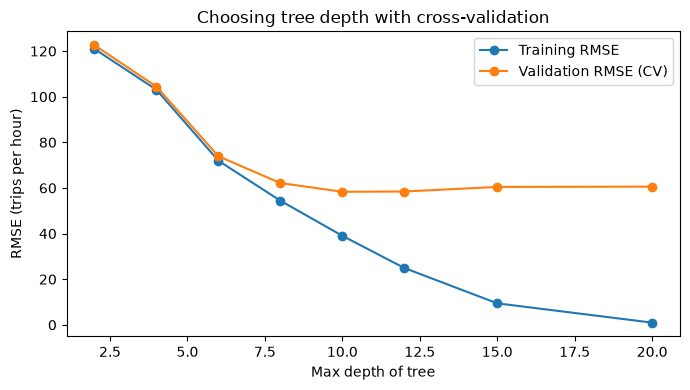

In [13]:
# Bias-variance trade-off: training error keeps falling, validation error stops improving and goes up again
cv_results = pd.DataFrame(tree_search.cv_results_)
depths = cv_results["param_max_depth"]

plt.figure(figsize=(7, 4))
plt.plot(depths, -cv_results["mean_train_score"], marker="o", label="Training RMSE")
plt.plot(depths, -cv_results["mean_test_score"], marker="o", label="Validation RMSE (CV)")
plt.xlabel("Max depth of tree")
plt.ylabel("RMSE (trips per hour)")
plt.title("Choosing tree depth with cross-validation")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "02_tree_depth_cv.png", dpi=150)
plt.show()

### Random forest
Many deep trees, each trained on a bootstrap sample and only allowed to look at half of the features at each split. Averaging them reduces the variance of a single tree.

In [14]:
forest = RandomForestRegressor(
    n_estimators=300,
    max_features=0.5,
    min_samples_leaf=2,
    n_jobs=-1,
    random_state=42,
)
forest.fit(train[tree_features], y_train)
evaluate("Random forest", forest.predict(test[tree_features]))

{'model': 'Random forest', 'RMSE': 50.27832745529282, 'MAE': 33.44087536071156, 'R2': 0.8919272609488809}


### Gradient boosting
Trees are built one after another, each one correcting the errors of the previous ones. We use the Poisson loss, since the target is a count.

In [15]:
boosting = HistGradientBoostingRegressor(loss="poisson", max_iter=500, learning_rate=0.05, random_state=42)
boosting.fit(train[tree_features], y_train)
evaluate("Gradient boosting", boosting.predict(test[tree_features]))

{'model': 'Gradient boosting', 'RMSE': 47.50420421994023, 'MAE': 29.36526841382169, 'R2': 0.903524151050134}


## 6. Comparison

In [16]:
results_table = pd.DataFrame(results).set_index("model").round(3)
results_table

,RMSE,MAE,R2
model,,,
Baseline (mean),152.943,120.872,-0.000
Linear regression,86.994,65.131,0.676
Poisson regression,70.810,48.214,0.786
Linear regression + hour × day type,74.290,55.204,0.764
Poisson regression + hour × day type,55.863,37.216,0.867
Decision tree,60.512,39.437,0.843
Random forest,50.278,33.441,0.892
Gradient boosting,47.504,29.365,0.904


### Example: one test week

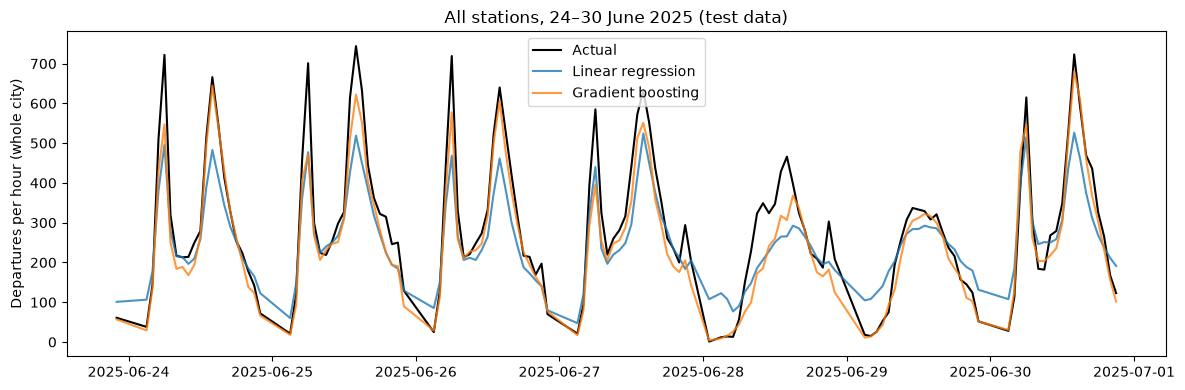

Largest actual hour in this week: 744
Largest predicted hour (gradient boosting): 681
Largest predicted hour (linear regression): 526
Negative linear predictions this week: 0 of 141 hours


,Actual peak,Linear peak,Boosting peak
date,,,
Tue 24 Jun,722,496.0,645.0
Wed 25 Jun,744,519.0,622.0
Thu 26 Jun,719,468.0,606.0
Fri 27 Jun,633,524.0,551.0
Sat 28 Jun,466,292.0,368.0
Sun 29 Jun,337,293.0,322.0
Mon 30 Jun,723,526.0,681.0


In [18]:
test["pred_linear"] = linear.predict(test)
test["pred_boosting"] = boosting.predict(test[tree_features])

week = test[(test["date"] >= "2025-06-24") & (test["date"] <= "2025-06-30")]

plt.figure(figsize=(12, 4))
plt.plot(week["time"], week["departures"], label="Actual", color="black")
plt.plot(week["time"], week["pred_linear"], label="Linear regression", alpha=0.8)
plt.plot(week["time"], week["pred_boosting"], label="Gradient boosting", alpha=0.8)
plt.ylabel("Departures per hour (whole city)")
plt.title("All stations, 24–30 June 2025 (test data)")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "02_example_week.png", dpi=150)
plt.show()

## 7. Comparison with predicting single stations

For comparison, we train the same gradient boosting model on the station-level table, where the target is the number of departures from one station in one hour. The station is described by its position and its average demand in the training data. For speed, we use a random sample of 200 000 training rows.

In [19]:
station_is_test = df["date"].dt.day >= 24
station_mean = df[~station_is_test].groupby("station_id")["departures"].mean().rename("station_mean")
station_df = df.join(station_mean, on="station_id")
station_df["station_mean"] = station_df["station_mean"].fillna(df.loc[~station_is_test, "departures"].mean())

station_features = ["station_mean", "lat", "lon", "hour", "weekday", "month", "is_holiday"] + weather_features
station_train = station_df[~station_is_test].sample(n=200_000, random_state=42)
station_test = station_df[station_is_test]

station_boosting = HistGradientBoostingRegressor(loss="poisson", max_iter=300, random_state=42)
station_boosting.fit(station_train[station_features], station_train["departures"])
station_pred = station_boosting.predict(station_test[station_features])

print("Average departures per station-hour:", round(station_test["departures"].mean(), 2))
print("Station-level R², gradient boosting:", round(r2_score(station_test["departures"], station_pred), 3))

Average departures per station-hour: 0.6
Station-level R², gradient boosting: 0.388


## 8. Which features matter?

**Permutation importance**: shuffle one feature in the test set and see how much worse the model gets. A large drop means the model relies on that feature.

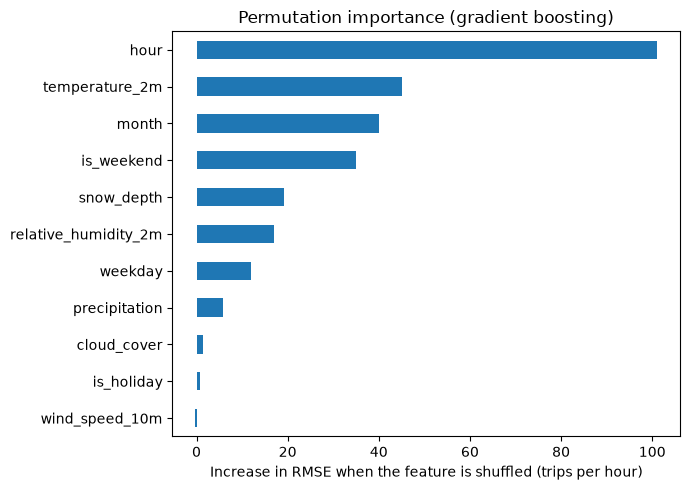

hour                    101.0
temperature_2m           45.1
month                    40.1
is_weekend               35.0
snow_depth               19.3
relative_humidity_2m     17.0
weekday                  12.0
precipitation             5.7
cloud_cover               1.5
is_holiday                0.7
wind_speed_10m           -0.2
dtype: float64

In [20]:
importance = permutation_importance(
    boosting, test[tree_features], y_test,
    scoring="neg_root_mean_squared_error", n_repeats=10, random_state=42,
)
importance_table = pd.Series(importance.importances_mean, index=tree_features).sort_values()

plt.figure(figsize=(7, 5))
importance_table.plot.barh()
plt.xlabel("Increase in RMSE when the feature is shuffled (trips per hour)")
plt.title("Permutation importance (gradient boosting)")
plt.tight_layout()
plt.savefig(FIG_DIR / "02_feature_importance.png", dpi=150)
plt.show()

importance_table.sort_values(ascending=False).round(1)